Directory 'kaggle_3m' already exists. Skipping extraction.
Number of MRI images: 3929
Number of masks: 3929


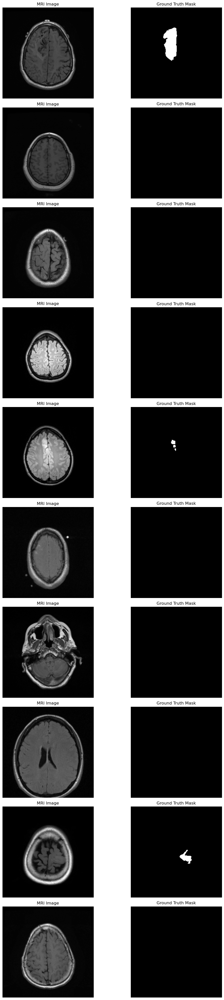

In [1]:
import os
import zipfile
import matplotlib.pyplot as plt
from glob import glob
import cv2
import random

zip_path = "kaggle_3m.zip"
extract_path = "kaggle_3m"

if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print(f"Extracted '{zip_path}' to '{extract_path}'")
else:
    print(f"Directory '{extract_path}' already exists. Skipping extraction.")

dataset_path = extract_path

all_files = sorted(glob(os.path.join(dataset_path, '**', '*.tif'), recursive=True))
image_files = [f for f in all_files if "_mask" not in f]  
mask_files = [f for f in all_files if "_mask" in f]  

print("Number of MRI images:", len(image_files))
print("Number of masks:", len(mask_files))

assert len(image_files) == len(mask_files), "Mismatch between number of images and masks!"

num_samples = min(10, len(image_files))
sample_indices = random.sample(range(len(image_files)), num_samples)

plt.figure(figsize=(12, 4 * num_samples))

for i, idx in enumerate(sample_indices):
    img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_files[idx], cv2.IMREAD_GRAYSCALE)

    plt.subplot(num_samples, 2, 2*i + 1)
    plt.imshow(img, cmap='gray')
    plt.title("MRI Image")
    plt.axis('off')
    
    plt.subplot(num_samples, 2, 2*i + 2)
    plt.imshow(mask, cmap='gray')
    plt.title("Ground Truth Mask")
    plt.axis('off')

plt.tight_layout()
plt.show()


Number of MRI images: 3929
Number of masks: 3929


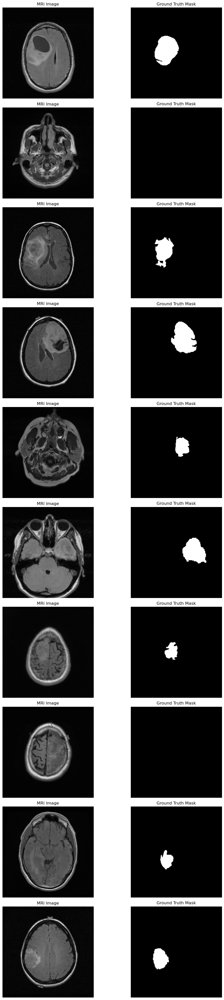

In [2]:
import os
import matplotlib.pyplot as plt
from glob import glob
import cv2
import random


all_files = sorted(glob(os.path.join(dataset_path, '**', '*.tif'), recursive=True))
image_files = [f for f in all_files if "_mask" not in f]  # MRI images
mask_files = [f for f in all_files if "_mask" in f]  # Ground truth masks

print("Number of MRI images:", len(image_files))
print("Number of masks:", len(mask_files))


assert len(image_files) == len(mask_files), "Mismatch between number of images and masks!"


num_samples = min(10, len(image_files))
sample_indices = random.sample(range(len(image_files)), num_samples)

plt.figure(figsize=(12, 4 * num_samples))

for i, idx in enumerate(sample_indices):
    img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_files[idx], cv2.IMREAD_GRAYSCALE)
    
  
    plt.subplot(num_samples, 2, 2*i + 1)
    plt.imshow(img, cmap='gray')
    plt.title("MRI Image")
    plt.axis('off')
    
    # Show ground truth mask
    plt.subplot(num_samples, 2, 2*i + 2)
    plt.imshow(mask, cmap='gray')
    plt.title("Ground Truth Mask")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [3]:
empty_masks = sum(cv2.countNonZero(cv2.imread(mask, cv2.IMREAD_GRAYSCALE)) == 0 for mask in mask_files)
print(f"Number of empty masks: {empty_masks}")
print(f"Percentage of empty masks: {100 * empty_masks / len(mask_files):.2f}%")


Number of empty masks: 2556
Percentage of empty masks: 65.05%


Total number of patients: 110
Number of images per patient:
TCGA_CS_4941_19960909: 23
TCGA_CS_4942_19970222: 20
TCGA_CS_4943_20000902: 20
TCGA_CS_4944_20010208: 20
TCGA_CS_5393_19990606: 20
TCGA_CS_5395_19981004: 20
TCGA_CS_5396_20010302: 24
TCGA_CS_5397_20010315: 22
TCGA_CS_6186_20000601: 25
TCGA_CS_6188_20010812: 24
TCGA_CS_6290_20000917: 20
TCGA_CS_6665_20010817: 24
TCGA_CS_6666_20011109: 26
TCGA_CS_6667_20011105: 20
TCGA_CS_6668_20011025: 28
TCGA_CS_6669_20020102: 22
TCGA_DU_5849_19950405: 38
TCGA_DU_5851_19950428: 40
TCGA_DU_5852_19950709: 36
TCGA_DU_5853_19950823: 36
TCGA_DU_5854_19951104: 36
TCGA_DU_5855_19951217: 26
TCGA_DU_5871_19941206: 36
TCGA_DU_5872_19950223: 71
TCGA_DU_5874_19950510: 38
TCGA_DU_6399_19830416: 53
TCGA_DU_6400_19830518: 57
TCGA_DU_6401_19831001: 51
TCGA_DU_6404_19850629: 53
TCGA_DU_6405_19851005: 60
TCGA_DU_6407_19860514: 58
TCGA_DU_6408_19860521: 56
TCGA_DU_7008_19830723: 52
TCGA_DU_7010_19860307: 58
TCGA_DU_7013_19860523: 49
TCGA_DU_7014_19860618: 60
TCGA

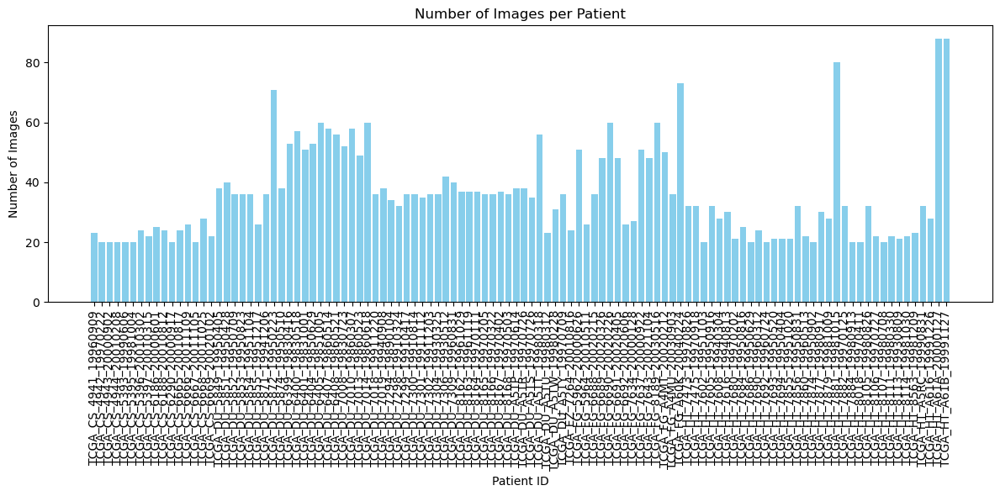

In [4]:
import os
from collections import Counter
import matplotlib.pyplot as plt


patient_ids = [os.path.basename(os.path.dirname(f)) for f in image_files]


patient_counts = Counter(patient_ids)


print("Total number of patients:", len(patient_counts))
print("Number of images per patient:")
for patient, count in patient_counts.items():
    print(f"{patient}: {count}")


plt.figure(figsize=(12, 6))
plt.bar(patient_counts.keys(), patient_counts.values(), color='skyblue')
plt.xlabel("Patient ID")
plt.ylabel("Number of Images")
plt.title("Number of Images per Patient")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

🔹 Dynamic noise threshold (percentile 10%): 1.0098727
Noisy images (below threshold): 393
Clean images (above threshold): 3536


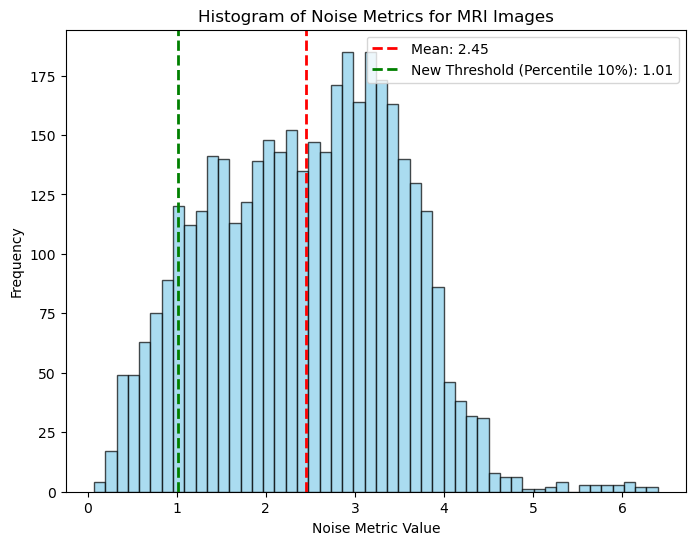

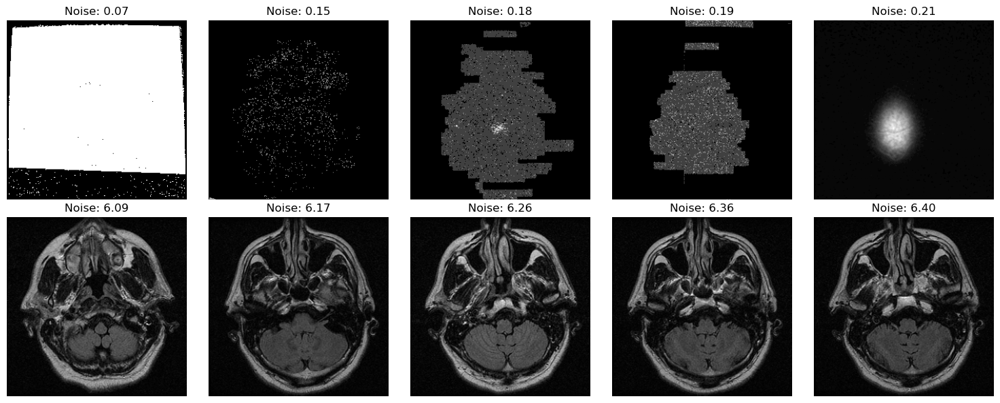

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

def noise_metric(image):
    img = image.astype(np.float32)
    median_filtered = cv2.medianBlur(image, 3)
    residual_median = img - median_filtered.astype(np.float32)
    noise_median = np.std(residual_median)
    
    gaussian_filtered = cv2.GaussianBlur(image, (3, 3), 0)
    residual_gaussian = img - gaussian_filtered.astype(np.float32)
    noise_gaussian = np.std(residual_gaussian)
    
    return (noise_median + noise_gaussian) / 2.0

noise_metrics = []
for image_path in image_files:
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    nm = noise_metric(img)
    noise_metrics.append(nm)
noise_metrics = np.array(noise_metrics)

threshold_noise = np.percentile(noise_metrics, 10) 

print("🔹 Dynamic noise threshold (percentile 10%):", threshold_noise)


noisy_indices = np.where(noise_metrics <= threshold_noise)[0]  
clean_indices = np.where(noise_metrics > threshold_noise)[0]  
print("Noisy images (below threshold):", len(noisy_indices))
print("Clean images (above threshold):", len(clean_indices))

plt.figure(figsize=(8,6))
plt.hist(noise_metrics, bins=50, color='skyblue', edgecolor='black', alpha=0.7)
plt.axvline(np.mean(noise_metrics), color='red', linestyle='dashed', linewidth=2, 
            label=f'Mean: {np.mean(noise_metrics):.2f}')
plt.axvline(threshold_noise, color='green', linestyle='dashed', linewidth=2, 
            label=f'New Threshold (Percentile 10%): {threshold_noise:.2f}')
plt.xlabel("Noise Metric Value")
plt.ylabel("Frequency")
plt.title("Histogram of Noise Metrics for MRI Images")
plt.legend()
plt.show()
num_to_display = 5

lowest_indices = np.argsort(noise_metrics)[:num_to_display]  
highest_indices = np.argsort(noise_metrics)[-num_to_display:]  

fig, axes = plt.subplots(2, num_to_display, figsize=(15,6))
for i, idx in enumerate(lowest_indices):
    img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    axes[0, i].imshow(img, cmap='gray')
    axes[0, i].set_title(f"Noise: {noise_metrics[idx]:.2f}")
    axes[0, i].axis('off')
    
for i, idx in enumerate(highest_indices):
    img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    axes[1, i].imshow(img, cmap='gray')
    axes[1, i].set_title(f"Noise: {noise_metrics[idx]:.2f}")
    axes[1, i].axis('off')

axes[0, 0].set_ylabel("Clean (Low Noise)", fontsize=12)
axes[1, 0].set_ylabel("Noisy (High Noise)", fontsize=12)
plt.tight_layout()
plt.show()


Counts per quality metric bin:
Quality metric in range 0 - 1: 387
Quality metric in range 1 - 2: 1006
Quality metric in range 2 - 3: 1212
Quality metric in range 3 - 4: 1133
Quality metric in range 4 - inf: 191

Decision Suggestions:
1. Images with quality metric < 1:
   - These images are extremely poor (e.g., very 'snowy' or underexposed).
   - Recommendation: need to be analyzed more carefully.

2. Images with quality metric between 1 and 4:
   - These images have moderate quality issues.
   - Recommendation: Apply advanced denoising techniques (e.g., Non-Local Means, BM3D, or deep learning based methods) to improve quality.

3. Images with quality metric >= 4:
   - These images are of acceptable quality and can be used as is.



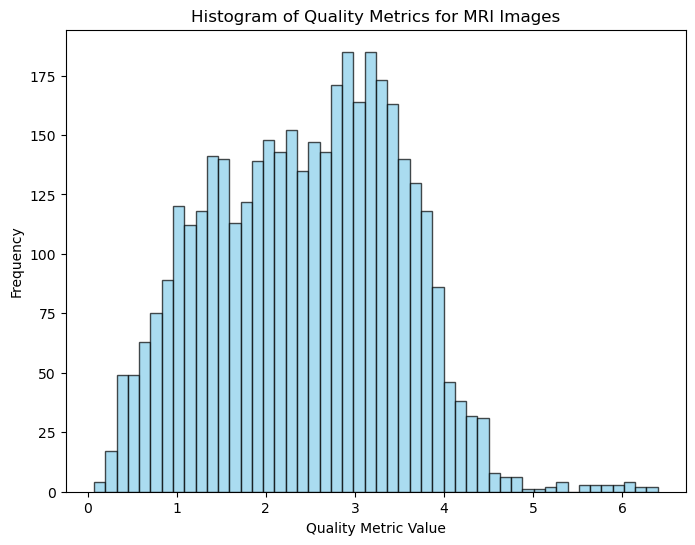

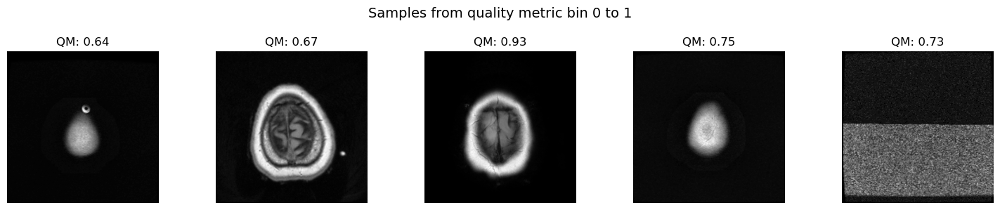

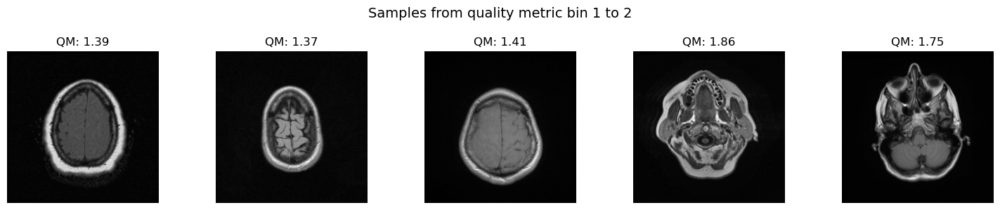

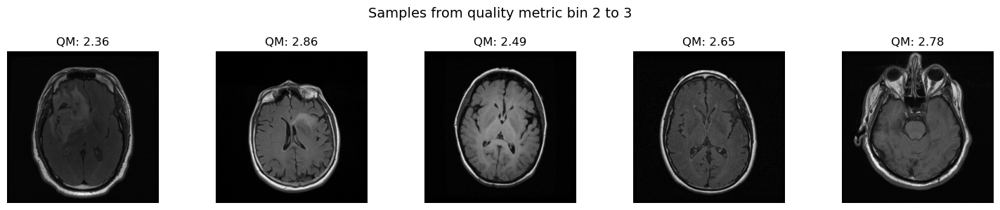

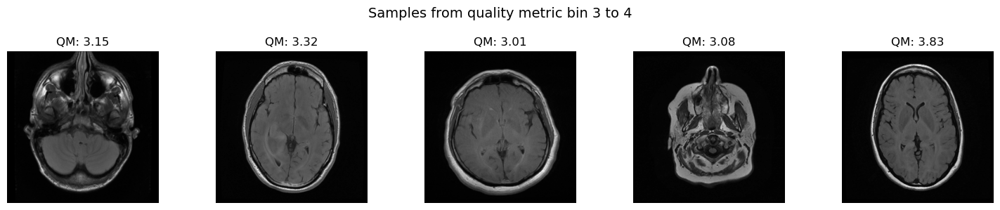

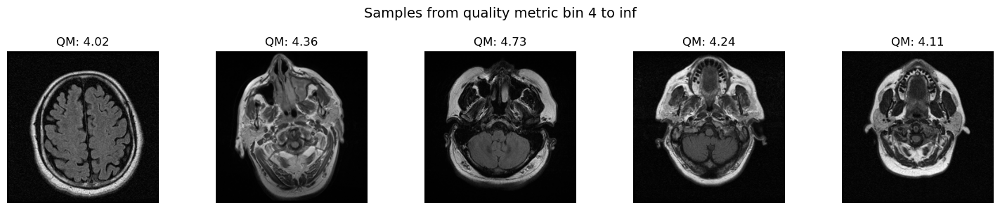

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

def quality_metric(image):
    img = image.astype(np.float32)
    median_filtered = cv2.medianBlur(image, 3)
    residual_median = img - median_filtered.astype(np.float32)
    noise_median = np.std(residual_median)
    
    gaussian_filtered = cv2.GaussianBlur(image, (3, 3), 0)
    residual_gaussian = img - gaussian_filtered.astype(np.float32)
    noise_gaussian = np.std(residual_gaussian)
    
    return (noise_median + noise_gaussian) / 2.0

quality_metrics = []
for image_path in image_files:
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    q = quality_metric(img)
    quality_metrics.append(q)
quality_metrics = np.array(quality_metrics)

bins = [(0,1), (1,2), (2,3), (3,4), (4, float('inf'))]
bin_counts = {}
for (low, high) in bins:
    count = np.sum((quality_metrics >= low) & (quality_metrics < high))
    bin_counts[f"{low} - {high if high != float('inf') else 'inf'}"] = count

print("Counts per quality metric bin:")
for key, count in bin_counts.items():
    print(f"Quality metric in range {key}: {count}")

print("\nDecision Suggestions:")
print("1. Images with quality metric < 1:")
print("   - These images are extremely poor (e.g., very 'snowy' or underexposed).")
print("   - Recommendation: need to be analyzed more carefully.")
print("")
print("2. Images with quality metric between 1 and 4:")
print("   - These images have moderate quality issues.")
print("   - Recommendation: Apply advanced denoising techniques (e.g., Non-Local Means, BM3D, or deep learning based methods) to improve quality.")
print("")
print("3. Images with quality metric >= 4:")
print("   - These images are of acceptable quality and can be used as is.")
print("")

plt.figure(figsize=(8,6))
plt.hist(quality_metrics, bins=50, color='skyblue', edgecolor='black', alpha=0.7)
plt.xlabel("Quality Metric Value")
plt.ylabel("Frequency")
plt.title("Histogram of Quality Metrics for MRI Images")
plt.show()

def display_samples_for_bin(low, high, num_samples=5):
    indices = np.where((quality_metrics >= low) & (quality_metrics < high))[0]
    if len(indices) == 0:
        print(f"No images in bin {low} to {high}")
        return
    sample_indices = np.random.choice(indices, min(len(indices), num_samples), replace=False)
    fig, axes = plt.subplots(1, len(sample_indices), figsize=(15, 3))
    fig.suptitle(f"Samples from quality metric bin {low} to {high}", fontsize=14)
    for i, idx in enumerate(sample_indices):
        img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(f"QM: {quality_metrics[idx]:.2f}")
        axes[i].axis('off')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

for (low, high) in bins:
    display_samples_for_bin(low, high)


Processing bin: Low Quality (<1) (Total images in bin: 387)


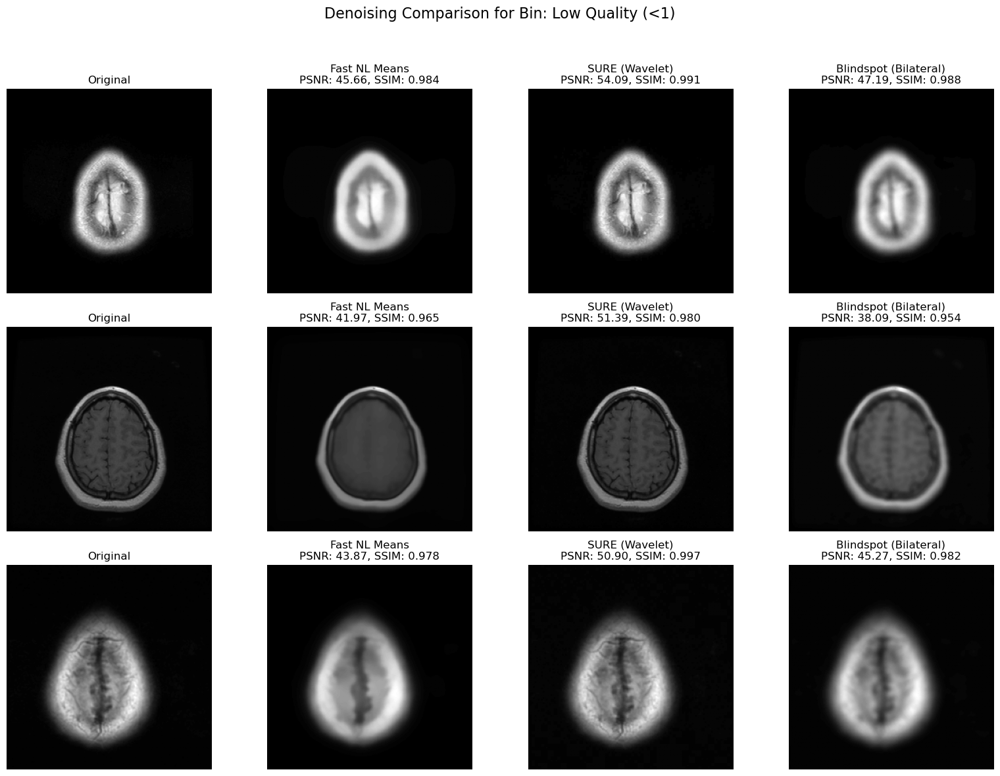

Average Metrics for Bin: Low Quality (<1)
Fast NL Means -> Average PSNR: 43.83, Average SSIM: 0.976
SURE (Wavelet) -> Average PSNR: 52.13, Average SSIM: 0.989
Blindspot (Bilateral) -> Average PSNR: 43.52, Average SSIM: 0.974

Processing bin: Moderate Quality (1-4) (Total images in bin: 3351)


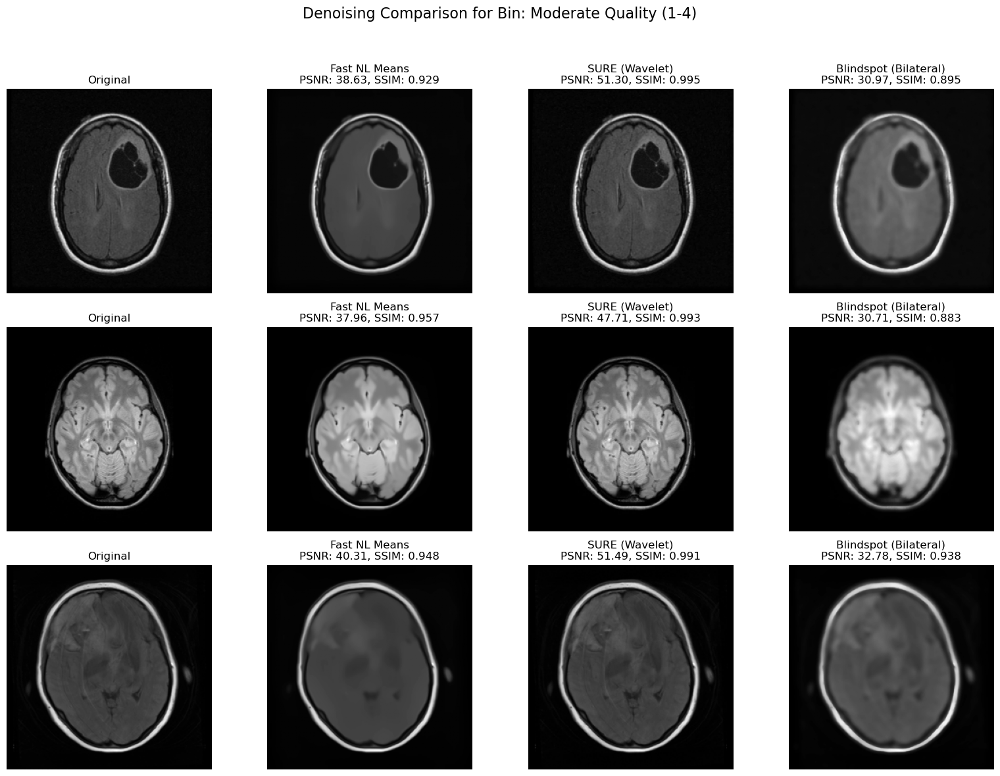

Average Metrics for Bin: Moderate Quality (1-4)
Fast NL Means -> Average PSNR: 38.97, Average SSIM: 0.945
SURE (Wavelet) -> Average PSNR: 50.17, Average SSIM: 0.993
Blindspot (Bilateral) -> Average PSNR: 31.49, Average SSIM: 0.905

Processing bin: High Quality (>=4) (Total images in bin: 191)


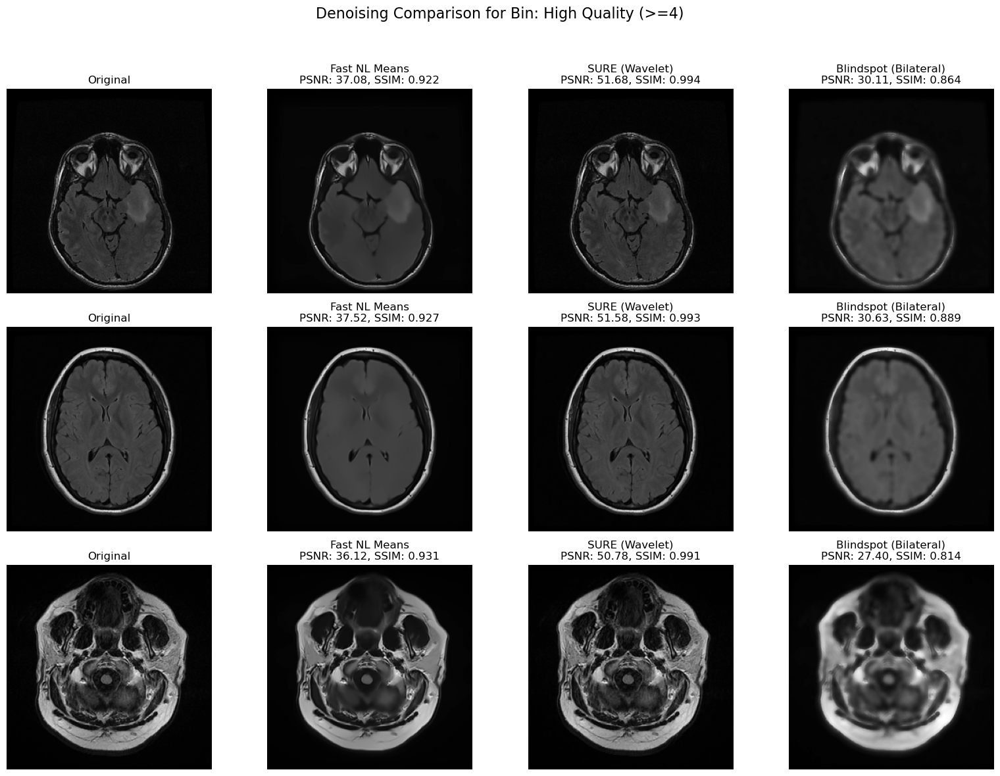

Average Metrics for Bin: High Quality (>=4)
Fast NL Means -> Average PSNR: 36.91, Average SSIM: 0.927
SURE (Wavelet) -> Average PSNR: 51.35, Average SSIM: 0.993
Blindspot (Bilateral) -> Average PSNR: 29.38, Average SSIM: 0.856

Overall Denoising Metrics Summary:
Fast NL Means -> Overall Average PSNR: 39.90, Overall Average SSIM: 0.949
SURE (Wavelet) -> Overall Average PSNR: 51.21, Overall Average SSIM: 0.992
Blindspot (Bilateral) -> Overall Average PSNR: 34.79, Overall Average SSIM: 0.912


In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.restoration import denoise_wavelet


def denoise_fastNlMeans(img, h=10):
    return cv2.fastNlMeansDenoising(img, h=h)

def denoise_sure(img):
    img_float = img.astype(np.float32) / 255.0
    denoised = denoise_wavelet(img_float, channel_axis=None,
                               method='BayesShrink', mode='soft', rescale_sigma=True)
    denoised = np.clip(denoised * 255, 0, 255).astype(np.uint8)
    return denoised

def denoise_blindspot(img):
    return cv2.bilateralFilter(img, d=9, sigmaColor=75, sigmaSpace=75)

denoising_methods = [
    ("Fast NL Means", denoise_fastNlMeans),
    ("SURE (Wavelet)", denoise_sure),
    ("Blindspot (Bilateral)", denoise_blindspot)
]

quality_metrics = np.array(quality_metrics)
bin1_indices = np.where(quality_metrics < 1)[0]                      
bin2_indices = np.where((quality_metrics >= 1) & (quality_metrics < 4))[0] 
bin3_indices = np.where(quality_metrics >= 4)[0]                     

bins = {
    "Low Quality (<1)": bin1_indices,
    "Moderate Quality (1-4)": bin2_indices,
    "High Quality (>=4)": bin3_indices
}

num_samples = 3
results_summary = {}

for bin_name, indices in bins.items():
    print(f"\nProcessing bin: {bin_name} (Total images in bin: {len(indices)})")
    if len(indices) == 0:
        print("No images in this bin.")
        continue

    sample_indices = random.sample(list(indices), min(num_samples, len(indices)))
    
    bin_metrics = {method_name: {"psnr": [], "ssim": []} for method_name, _ in denoising_methods}
    n_methods = len(denoising_methods) + 1  
    fig, axes = plt.subplots(len(sample_indices), n_methods, figsize=(4 * n_methods, 4 * len(sample_indices)))
    if len(sample_indices) == 1:
        axes = np.expand_dims(axes, axis=0)
    for row_idx, img_idx in enumerate(sample_indices):
        original = cv2.imread(image_files[img_idx], cv2.IMREAD_GRAYSCALE)
        ax = axes[row_idx, 0] if n_methods > 1 else axes[row_idx]
        ax.imshow(original, cmap='gray')
        ax.set_title("Original")
        ax.axis('off')
        
        for col_idx, (method_name, denoise_func) in enumerate(denoising_methods, start=1):
            try:
                denoised = denoise_func(original)
            except Exception as e:
                print(f"Error in method {method_name}: {e}")
                denoised = original.copy()
            
            psnr_val = peak_signal_noise_ratio(original, denoised)
            ssim_val = structural_similarity(original, denoised)
            
            bin_metrics[method_name]["psnr"].append(psnr_val)
            bin_metrics[method_name]["ssim"].append(ssim_val)
            
            ax = axes[row_idx, col_idx] if n_methods > 1 else axes[row_idx]
            ax.imshow(denoised, cmap='gray')
            ax.set_title(f"{method_name}\nPSNR: {psnr_val:.2f}, SSIM: {ssim_val:.3f}")
            ax.axis('off')
    
    plt.suptitle(f"Denoising Comparison for Bin: {bin_name}", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()
    
    print(f"Average Metrics for Bin: {bin_name}")
    for method_name in bin_metrics:
        avg_psnr = np.mean(bin_metrics[method_name]["psnr"]) if bin_metrics[method_name]["psnr"] else float('nan')
        avg_ssim = np.mean(bin_metrics[method_name]["ssim"]) if bin_metrics[method_name]["ssim"] else float('nan')
        print(f"{method_name} -> Average PSNR: {avg_psnr:.2f}, Average SSIM: {avg_ssim:.3f}")
        if method_name not in results_summary:
            results_summary[method_name] = {"psnr": [], "ssim": []}
        results_summary[method_name]["psnr"].append(avg_psnr)
        results_summary[method_name]["ssim"].append(avg_ssim)


print("\nOverall Denoising Metrics Summary:")
for method_name in results_summary:
    overall_psnr = np.mean(results_summary[method_name]["psnr"])
    overall_ssim = np.mean(results_summary[method_name]["ssim"])
    print(f"{method_name} -> Overall Average PSNR: {overall_psnr:.2f}, Overall Average SSIM: {overall_ssim:.3f}")


Total snowy images detected: 200


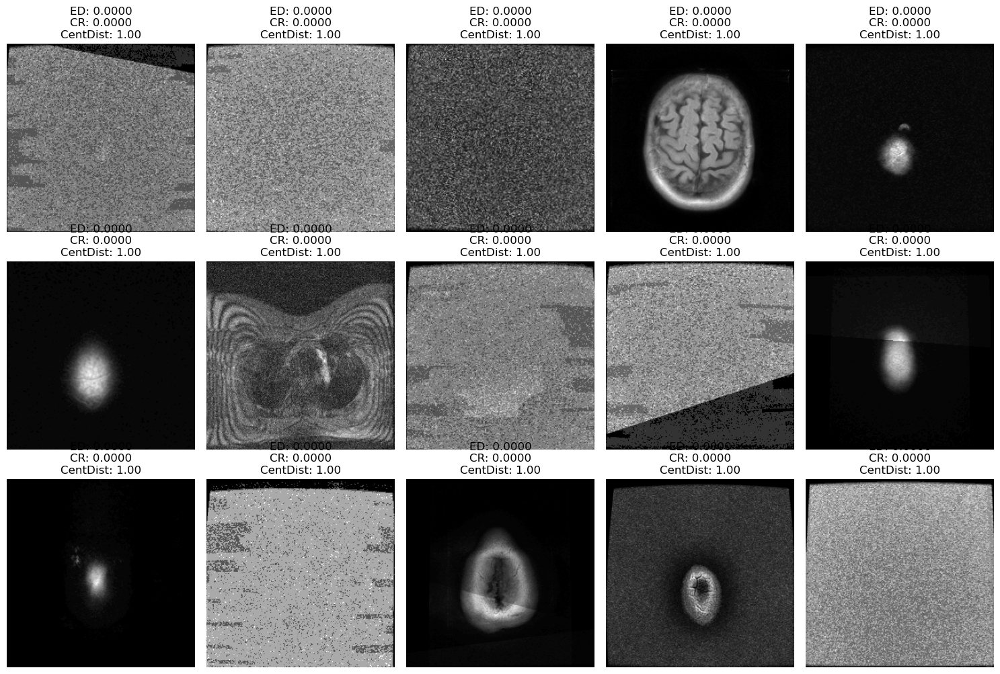

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

canny_low_threshold = 50
canny_high_threshold = 150


kernel_size = 5
kernel = np.ones((kernel_size, kernel_size), np.uint8)
ed_threshold = 0.003           
ct_threshold = 0.01            
centroid_distance_threshold = 0.3  

snowy_indices = []

for idx, img_path in enumerate(image_files):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    h, w = img.shape
    total_area = h * w

    edges = cv2.Canny(img, canny_low_threshold, canny_high_threshold)
    dilated_edges = cv2.dilate(edges, kernel, iterations=1)
    
    edge_density = np.count_nonzero(dilated_edges) / total_area
    
    contours, _ = cv2.findContours(dilated_edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        snowy_indices.append(idx)
        continue
    largest_contour = max(contours, key=cv2.contourArea)
    largest_contour_area = cv2.contourArea(largest_contour)
    structure_ratio = largest_contour_area / total_area
    M = cv2.moments(largest_contour)
    if M["m00"] != 0:
        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])
    else:
        cx, cy = 0, 0

    center_x, center_y = w // 2, h // 2
    distance = np.sqrt((cx - center_x)**2 + (cy - center_y)**2)
    max_distance = np.sqrt((center_x)**2 + (center_y)**2)
    norm_distance = distance / max_distance
    if (edge_density < ed_threshold) and (structure_ratio < ct_threshold) and (norm_distance > centroid_distance_threshold):
        snowy_indices.append(idx)

print(f"Total snowy images detected: {len(snowy_indices)}")

num_display = min(15, len(snowy_indices))
sample_indices = random.sample(snowy_indices, num_display) if snowy_indices else []

plt.figure(figsize=(15, 10))
for i, idx in enumerate(sample_indices):
    img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    h, w = img.shape
    total_area = h * w
    edges = cv2.Canny(img, canny_low_threshold, canny_high_threshold)
    dilated_edges = cv2.dilate(edges, kernel, iterations=1)
    edge_density = np.count_nonzero(dilated_edges) / total_area
    contours, _ = cv2.findContours(dilated_edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        largest_contour_area = cv2.contourArea(largest_contour)
        structure_ratio = largest_contour_area / total_area
        M = cv2.moments(largest_contour)
        if M["m00"] != 0:
            cx = int(M["m10"] / M["m00"])
            cy = int(M["m01"] / M["m00"])
        else:
            cx, cy = 0, 0
        center_x, center_y = w // 2, h // 2
        distance = np.sqrt((cx - center_x)**2 + (cy - center_y)**2)
        max_distance = np.sqrt((center_x)**2 + (center_y)**2)
        norm_distance = distance / max_distance
    else:
        structure_ratio = 0
        norm_distance = 1  

    plt.subplot(3, 5, i+1)
    plt.imshow(img, cmap='gray')
    plt.title(f"ED: {edge_density:.4f}\nCR: {structure_ratio:.4f}\nCentDist: {norm_distance:.2f}")
    plt.axis('off')
plt.tight_layout()
plt.show()


Total images originally: 3929
Snowy images removed: 200
Total images remaining after removal: 3729
Total moderate quality images (QM between 1 and 4): 3336
Total images denoised (moderate quality group): 3336


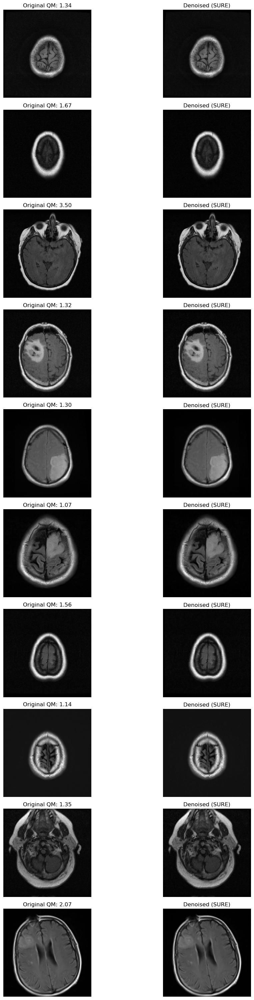

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

total_images = len(image_files)
all_indices = set(range(total_images))
remaining_indices = sorted(list(all_indices - set(snowy_indices)))

print("Total images originally:", total_images)
print("Snowy images removed:", len(snowy_indices))
print("Total images remaining after removal:", len(remaining_indices))

moderate_quality_indices = [idx for idx in remaining_indices if 1 <= quality_metrics[idx] < 4]
print("Total moderate quality images (QM between 1 and 4):", len(moderate_quality_indices))

denoised_results = {}  
for idx in moderate_quality_indices:
    img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    denoised_img = denoise_sure(img)
    denoised_results[idx] = denoised_img

print("Total images denoised (moderate quality group):", len(denoised_results))

num_display = min(10, len(moderate_quality_indices))
sample_indices = random.sample(moderate_quality_indices, num_display)

plt.figure(figsize=(12, num_display * 3))
for i, idx in enumerate(sample_indices):
    orig_img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    denoised_img = denoised_results[idx]
    
    plt.subplot(num_display, 2, 2*i + 1)
    plt.imshow(orig_img, cmap='gray')
    plt.title(f"Original QM: {quality_metrics[idx]:.2f}")
    plt.axis('off')
    
    plt.subplot(num_display, 2, 2*i + 2)
    plt.imshow(denoised_img, cmap='gray')
    plt.title("Denoised (SURE)")
    plt.axis('off')

plt.tight_layout()
plt.show()


In [10]:
import cv2

total_images = len(image_files)
all_indices = set(range(total_images))
remaining_indices = sorted(list(all_indices - set(snowy_indices)))  
moderate_quality_indices = [idx for idx in remaining_indices if 1 <= quality_metrics[idx] < 4]
clean_quality_indices = [idx for idx in remaining_indices if quality_metrics[idx] >= 4]

print("Total images originally:", total_images)
print("Snowy images removed:", len(snowy_indices))
print("Total images remaining after removal (expected: 3729):", len(remaining_indices))
print("Total moderate quality images (to be denoised, QM between 1 and 4):", len(moderate_quality_indices))
print("Total clean images (QM >= 4):", len(clean_quality_indices))
print("-" * 50)

denoised_dimensions = {} 
for idx in moderate_quality_indices:
    denoised_img = denoised_results.get(idx, None)
    if denoised_img is not None:
        denoised_dimensions[idx] = denoised_img.shape  
    else:
        img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
        denoised_dimensions[idx] = img.shape

clean_dimensions = {} 
for idx in clean_quality_indices:
    img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    clean_dimensions[idx] = img.shape
unique_denoised_dims = set(denoised_dimensions.values())
unique_clean_dims = set(clean_dimensions.values())

print("Unique dimensions for denoised images:", unique_denoised_dims)
print("Unique dimensions for clean images:", unique_clean_dims)
print("-" * 50)

print("Sample denoised image dimensions:")
sample_denoised = list(denoised_dimensions.items())[:5]
for idx, dims in sample_denoised:
    print(f"Index {idx}: {dims}")

print("\nSample clean image dimensions:")
sample_clean = list(clean_dimensions.items())[:5]
for idx, dims in sample_clean:
    print(f"Index {idx}: {dims}")


Total images originally: 3929
Snowy images removed: 200
Total images remaining after removal (expected: 3729): 3729
Total moderate quality images (to be denoised, QM between 1 and 4): 3336
Total clean images (QM >= 4): 191
--------------------------------------------------
Unique dimensions for denoised images: {(256, 256)}
Unique dimensions for clean images: {(256, 256)}
--------------------------------------------------
Sample denoised image dimensions:
Index 0: (256, 256)
Index 1: (256, 256)
Index 2: (256, 256)
Index 3: (256, 256)
Index 4: (256, 256)

Sample clean image dimensions:
Index 289: (256, 256)
Index 290: (256, 256)
Index 299: (256, 256)
Index 399: (256, 256)
Index 400: (256, 256)


Total images originally: 3929
Snowy images removed: 200
Total images remaining after removal: 3729
Total images to be denoised (QM < 4): 3538
Total clean images (QM >= 4): 191
--------------------------------------------------
Total images denoised (QM < 4): 3538


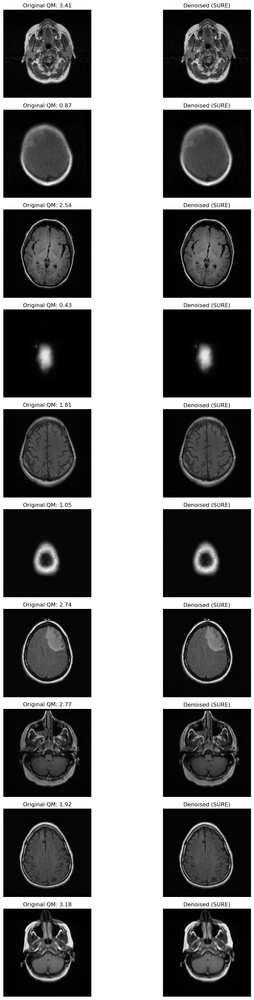

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

total_images = len(image_files)
all_indices = set(range(total_images))
remaining_indices = sorted(list(all_indices - set(snowy_indices)))

print("Total images originally:", total_images)
print("Snowy images removed:", len(snowy_indices))
print("Total images remaining after removal:", len(remaining_indices))

denoise_indices = [idx for idx in remaining_indices if quality_metrics[idx] < 4]
clean_indices   = [idx for idx in remaining_indices if quality_metrics[idx] >= 4]

print("Total images to be denoised (QM < 4):", len(denoise_indices))
print("Total clean images (QM >= 4):", len(clean_indices))
print("-" * 50)


denoised_results = {}  
for idx in denoise_indices:
    img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    denoised_img = denoise_sure(img)
    denoised_results[idx] = denoised_img

print("Total images denoised (QM < 4):", len(denoised_results))
num_display = min(10, len(denoised_results))
sample_indices = random.sample(list(denoised_results.keys()), num_display)

plt.figure(figsize=(12, num_display * 3))
for i, idx in enumerate(sample_indices):
    orig_img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    denoised_img = denoised_results[idx]
    plt.subplot(num_display, 2, 2*i + 1)
    plt.imshow(orig_img, cmap='gray')
    plt.title(f"Original QM: {quality_metrics[idx]:.2f}")
    plt.axis('off')

    plt.subplot(num_display, 2, 2*i + 2)
    plt.imshow(denoised_img, cmap='gray')
    plt.title("Denoised (SURE)")
    plt.axis('off')

plt.tight_layout()
plt.show()


Total available normalized images: 3729


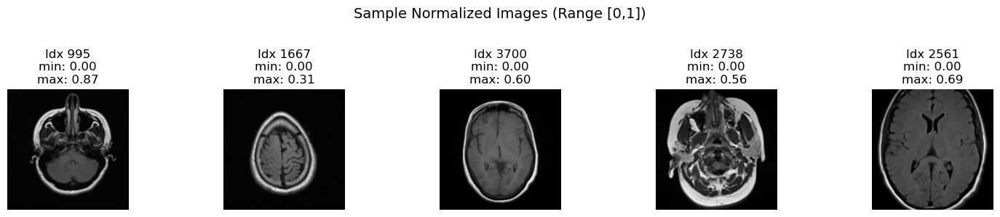

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

normalized_images = {}  

for idx in remaining_indices:
    if idx in denoised_results:
        img = denoised_results[idx]
    else:
        img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE)
    norm_img = img.astype(np.float32) / 255.0
    normalized_images[idx] = norm_img

print("Total available normalized images:", len(normalized_images))

sample_indices = random.sample(remaining_indices, 5)
plt.figure(figsize=(15, 3))
for i, idx in enumerate(sample_indices):
    norm_img = normalized_images[idx]
    plt.subplot(1, 5, i+1)
    plt.imshow(norm_img, cmap='gray')
    plt.title(f"Idx {idx}\nmin: {norm_img.min():.2f}\nmax: {norm_img.max():.2f}")
    plt.axis('off')
plt.suptitle("Sample Normalized Images (Range [0,1])", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()


In [13]:
import os
import random
from collections import defaultdict


patient_to_indices = defaultdict(list)
for idx in remaining_indices:
    patient_id = os.path.basename(os.path.dirname(image_files[idx]))
    patient_to_indices[patient_id].append(idx)


patient_image_counts = {pid: len(idxs) for pid, idxs in patient_to_indices.items()}
total_patients = len(patient_image_counts)
print("Total number of patients in available data:", total_patients)

total_available = len(remaining_indices)
print("Total available images (after snowy removal):", total_available)

#
train_indices = []
val_indices = []
test_indices = []

for patient, indices in patient_to_indices.items():
    random.shuffle(indices)
    n = len(indices)
    
    
    train_count = int(n * 0.8)
    val_count = int(n * 0.1)
    test_count = n - train_count - val_count  
    

    if train_count == 0 and n > 0:
        train_count = 1
    if val_count == 0 and n - train_count > 0:
        val_count = 1
    if (n - train_count - val_count) <= 0 and n - train_count - val_count < 0:
        test_count = n - train_count - val_count
    
    train_indices.extend(indices[:train_count])
    val_indices.extend(indices[train_count:train_count+val_count])
    test_indices.extend(indices[train_count+val_count:])


print("\n--- Group Stratified Split ---")
print(f"Total images originally: {total_available}")
print(f"Train: {len(train_indices)}")
print(f"Validation: {len(val_indices)}")
print(f"Test: {len(test_indices)}")
print(f"Sum: {len(train_indices) + len(val_indices) + len(test_indices)} (Expected: {total_available})")


train_ratio = len(train_indices) / total_available * 100
val_ratio = len(val_indices) / total_available * 100
test_ratio = len(test_indices) / total_available * 100
print(f"Approximate Ratios -> Train: {train_ratio:.2f}%, Val: {val_ratio:.2f}%, Test: {test_ratio:.2f}%")


train_masks = [mask_files[idx] for idx in train_indices]
val_masks = [mask_files[idx] for idx in val_indices]
test_masks = [mask_files[idx] for idx in test_indices]

print("\nSample split info:")
if train_indices:
    print(f"First train image: {image_files[train_indices[0]]}\n  Mask: {train_masks[0]}")
if val_indices:
    print(f"First validation image: {image_files[val_indices[0]]}\n  Mask: {val_masks[0]}")
if test_indices:
    print(f"First test image: {image_files[test_indices[0]]}\n  Mask: {test_masks[0]}")


Total number of patients in available data: 110
Total available images (after snowy removal): 3729

--- Group Stratified Split ---
Total images originally: 3729
Train: 2941
Validation: 335
Test: 453
Sum: 3729 (Expected: 3729)
Approximate Ratios -> Train: 78.87%, Val: 8.98%, Test: 12.15%

Sample split info:
First train image: kaggle_3m/kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_4.tif
  Mask: kaggle_3m/kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_4_mask.tif
First validation image: kaggle_3m/kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_10.tif
  Mask: kaggle_3m/kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_11_mask.tif
First test image: kaggle_3m/kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_19.tif
  Mask: kaggle_3m/kaggle_3m/TCGA_CS_4941_19960909/TCGA_CS_4941_19960909_1_mask.tif


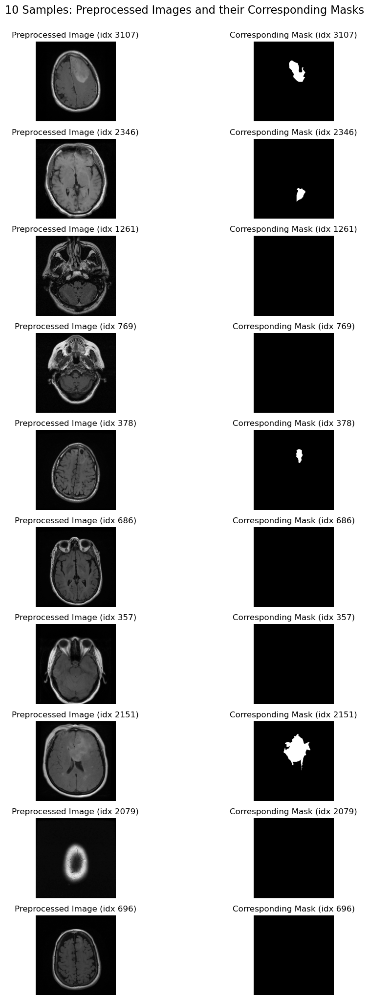

In [14]:
import matplotlib.pyplot as plt
import random
import cv2

sample_display = random.sample(remaining_indices, 10)

plt.figure(figsize=(12, 20))
for i, idx in enumerate(sample_display):
    preprocessed_img = normalized_images[idx]
    mask_img = cv2.imread(mask_files[idx], cv2.IMREAD_GRAYSCALE)
    
    plt.subplot(10, 2, 2 * i + 1)
    plt.imshow(preprocessed_img, cmap='gray')
    plt.title(f'Preprocessed Image (idx {idx})')
    plt.axis('off')
    

    plt.subplot(10, 2, 2 * i + 2)
    plt.imshow(mask_img, cmap='gray')
    plt.title(f'Corresponding Mask (idx {idx})')
    plt.axis('off')

plt.tight_layout()
plt.suptitle("10 Samples: Preprocessed Images and their Corresponding Masks", fontsize=16, y=1.02)
plt.show()


Current training image counts per patient:
  TCGA_CS_4941_19960909: 18
  TCGA_CS_4942_19970222: 14
  TCGA_CS_4943_20000902: 15
  TCGA_CS_4944_20010208: 16
  TCGA_CS_5393_19990606: 16
  TCGA_CS_5395_19981004: 15
  TCGA_CS_5396_20010302: 18
  TCGA_CS_5397_20010315: 17
  TCGA_CS_6186_20000601: 19
  TCGA_CS_6188_20010812: 16
  TCGA_CS_6290_20000917: 16
  TCGA_CS_6665_20010817: 17
  TCGA_CS_6666_20011109: 20
  TCGA_CS_6667_20011105: 16
  TCGA_CS_6668_20011025: 20
  TCGA_CS_6669_20020102: 16
  TCGA_DU_5849_19950405: 28
  TCGA_DU_5851_19950428: 27
  TCGA_DU_5852_19950709: 28
  TCGA_DU_5853_19950823: 27
  TCGA_DU_5854_19951104: 27
  TCGA_DU_5855_19951217: 19
  TCGA_DU_5871_19941206: 26
  TCGA_DU_5872_19950223: 52
  TCGA_DU_5874_19950510: 28
  TCGA_DU_6399_19830416: 40
  TCGA_DU_6400_19830518: 44
  TCGA_DU_6401_19831001: 40
  TCGA_DU_6404_19850629: 41
  TCGA_DU_6405_19851005: 44
  TCGA_DU_6407_19860514: 44
  TCGA_DU_6408_19860521: 42
  TCGA_DU_7008_19830723: 40
  TCGA_DU_7010_19860307: 44
  TCG

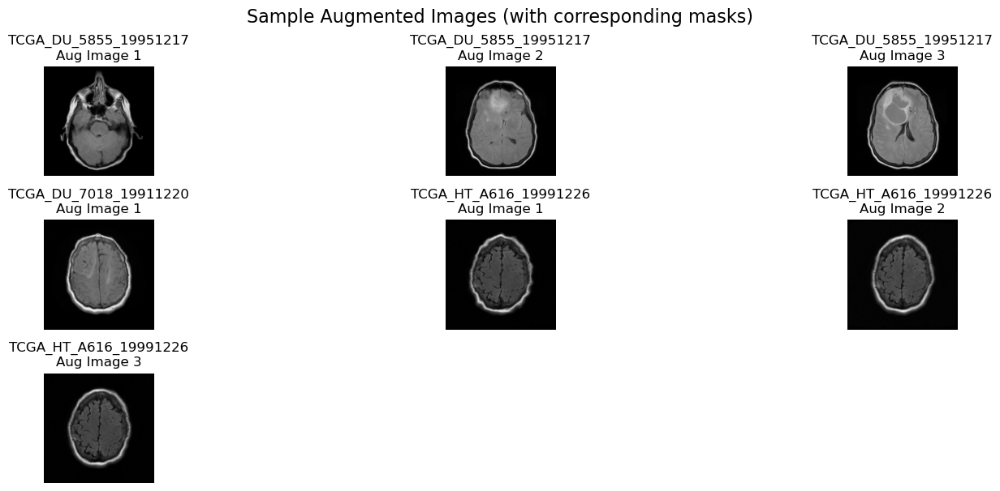


Final training image counts per patient (original + augmented):
TCGA_CS_4941_19960909: 26
TCGA_CS_4942_19970222: 26
TCGA_CS_4943_20000902: 26
TCGA_CS_4944_20010208: 26
TCGA_CS_5393_19990606: 26
TCGA_CS_5395_19981004: 26
TCGA_CS_5396_20010302: 26
TCGA_CS_5397_20010315: 26
TCGA_CS_6186_20000601: 26
TCGA_CS_6188_20010812: 26
TCGA_CS_6290_20000917: 26
TCGA_CS_6665_20010817: 26
TCGA_CS_6666_20011109: 26
TCGA_CS_6667_20011105: 26
TCGA_CS_6668_20011025: 26
TCGA_CS_6669_20020102: 26
TCGA_DU_5849_19950405: 28
TCGA_DU_5851_19950428: 27
TCGA_DU_5852_19950709: 28
TCGA_DU_5853_19950823: 27
TCGA_DU_5854_19951104: 27
TCGA_DU_5855_19951217: 26
TCGA_DU_5871_19941206: 26
TCGA_DU_5872_19950223: 52
TCGA_DU_5874_19950510: 28
TCGA_DU_6399_19830416: 40
TCGA_DU_6400_19830518: 44
TCGA_DU_6401_19831001: 40
TCGA_DU_6404_19850629: 41
TCGA_DU_6405_19851005: 44
TCGA_DU_6407_19860514: 44
TCGA_DU_6408_19860521: 42
TCGA_DU_7008_19830723: 40
TCGA_DU_7010_19860307: 44
TCGA_DU_7013_19860523: 39
TCGA_DU_7014_19860618: 45

In [15]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
from collections import defaultdict
from scipy.ndimage import gaussian_filter, map_coordinates

def elastic_transform_pair(image, mask, alpha, sigma, random_state=None):
    if random_state is None:
        random_state = np.random.RandomState(None)
    shape = image.shape

    dx = gaussian_filter((random_state.rand(*shape) * 2 - 1), sigma) * alpha
    dy = gaussian_filter((random_state.rand(*shape) * 2 - 1), sigma) * alpha

    x, y = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))
    indices = np.reshape(y + dy, (-1, 1)), np.reshape(x + dx, (-1, 1))
    
    distorted_image = map_coordinates(image, indices, order=1, mode='reflect').reshape(shape)
    distorted_mask = map_coordinates(mask, indices, order=0, mode='reflect').reshape(shape)
    
    return distorted_image, distorted_mask

def intensity_variation(image, brightness_range=(0.9, 1.1), contrast_range=(0.9, 1.1)):
    factor = np.random.uniform(*brightness_range)
    image = image * factor
    contrast_factor = np.random.uniform(*contrast_range)
    mean_val = np.mean(image)
    image = (image - mean_val) * contrast_factor + mean_val
    return np.clip(image, 0, 255).astype(np.uint8)

def augment_image_and_mask(image, mask):
    alpha = np.random.uniform(30, 40)
    sigma = np.random.uniform(4, 6)
    elastic_img, elastic_mask = elastic_transform_pair(image, mask, alpha=alpha, sigma=sigma)
    aug_img = intensity_variation(elastic_img, brightness_range=(0.9, 1.1), contrast_range=(0.9, 1.1))
    return aug_img, elastic_mask


train_indices_set = set(train_indices) 
train_patient_indices = {}
for pid, indices in patient_to_indices.items():
    train_idx = [idx for idx in indices if idx in train_indices_set]
    if train_idx: 
        train_patient_indices[pid] = train_idx


current_counts = {pid: len(idxs) for pid, idxs in train_patient_indices.items()}
print("Current training image counts per patient:")
for pid, count in current_counts.items():
    print(f"  {pid}: {count}")

all_counts = np.array(list(current_counts.values()))
target_count = int(np.percentile(all_counts, 60))
print(f"\nTarget image count per patient for balancing (60th percentile): {target_count}")


augmented_train_data = defaultdict(list)


for pid, indices in train_patient_indices.items():
    count = len(indices)
    num_to_augment = target_count - count
    if num_to_augment > 0:
        print(f"Patient {pid}: augmenting {num_to_augment} images.")
        for _ in range(num_to_augment):
            src_idx = random.choice(indices)
            if 'denoised_results' in globals() and src_idx in denoised_results:
                src_img = denoised_results[src_idx]
            else:
                src_img = cv2.imread(image_files[src_idx], cv2.IMREAD_GRAYSCALE)
            src_mask = cv2.imread(mask_files[src_idx], cv2.IMREAD_GRAYSCALE)
            aug_img, aug_mask = augment_image_and_mask(src_img, src_mask)
            augmented_train_data[pid].append((aug_img, aug_mask))


final_train_counts = {}
for pid in train_patient_indices:
    original_count = len(train_patient_indices[pid])
    augmented_count = len(augmented_train_data[pid])
    final_train_counts[pid] = original_count + augmented_count

print("\nFinal training image counts per patient (after augmentation):")
for pid, count in final_train_counts.items():
    print(f"  {pid}: {count}")


sample_patients = random.sample(list(train_patient_indices.keys()), min(5, len(train_patient_indices)))
plt.figure(figsize=(15, 10))
plot_index = 1
for pid in sample_patients:
    aug_pairs = augmented_train_data[pid]
    if len(aug_pairs) == 0:
        continue
    for i in range(min(3, len(aug_pairs))):
        aug_img, aug_mask = aug_pairs[i]
        plt.subplot(len(sample_patients), 3, plot_index)
        plt.imshow(aug_img, cmap='gray')
        plt.title(f"{pid}\nAug Image {i+1}")
        plt.axis('off')
        plot_index += 1
plt.suptitle("Sample Augmented Images (with corresponding masks)", fontsize=16)
plt.tight_layout()
plt.show()

print("\nFinal training image counts per patient (original + augmented):")
for pid in sorted(final_train_counts.keys()):
    print(f"{pid}: {final_train_counts[pid]}")


2026-05-04 20:38:11.185783: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-04 20:38:11.207038: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777927091.225324   23402 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777927091.230570   23402 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-05-04 20:38:11.253769: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

Loading data...


I0000 00:00:1777927096.438459   23402 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10127 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3080 Ti, pci bus id: 0000:00:06.0, compute capability: 8.6
/opt/conda/lib/python3.12/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(



--- Starting Master SOTA Training (Deeply Supervised U-Net) ---
Epoch 1/40


I0000 00:00:1777927113.561829   23790 service.cc:148] XLA service 0x7e7c4800cb50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1777927113.561944   23790 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce RTX 3080 Ti, Compute Capability 8.6
2026-05-04 20:38:34.008748: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1777927115.466083   23790 cuda_dnn.cc:529] Loaded cuDNN version 90501
2026-05-04 20:38:39.630573: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:378] Garbage collection: deallocate free memory regions (i.e., allocations) so that we can re-allocate a larger region to avoid OOM due to memory fragmentation. If you see this message frequently, you are running near the threshold of the available device memory and re-allocation may incur great performance overhead. You may try smaller batch s

  2/210 ━━━━━━━━━━━━━━━━━━━━ 17s 85ms/step - loss: 2.7897 - out1_dice_coef: 0.0162 - out1_iou_coef: 0.0082 - out1_loss: 1.5232 - out2_loss: 1.4353 - out3_loss: 1.4715 - out4_loss: 1.4471   

I0000 00:00:1777927130.399824   23790 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


210/210 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - loss: 1.8254 - out1_dice_coef: 0.1077 - out1_iou_coef: 0.0606 - out1_loss: 0.9778 - out2_loss: 0.9546 - out3_loss: 0.9775 - out4_loss: 1.0073
Epoch 1: val_out1_dice_coef improved from -inf to 0.31361, saving model to deep_unet_best.keras
210/210 ━━━━━━━━━━━━━━━━━━━━ 68s 183ms/step - loss: 1.8246 - out1_dice_coef: 0.1081 - out1_iou_coef: 0.0609 - out1_loss: 0.9773 - out2_loss: 0.9541 - out3_loss: 0.9771 - out4_loss: 1.0071 - val_loss: 1.4120 - val_out1_dice_coef: 0.3136 - val_out1_iou_coef: 0.1948 - val_out1_loss: 0.7401 - val_out2_loss: 0.7388 - val_out3_loss: 0.7680 - val_out4_loss: 0.8882
Epoch 2/40
210/210 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - loss: 1.4091 - out1_dice_coef: 0.3229 - out1_iou_coef: 0.2042 - out1_loss: 0.7359 - out2_loss: 0.7449 - out3_loss: 0.7738 - out4_loss: 0.8575 
Epoch 2: val_out1_dice_coef improved from 0.31361 to 0.33139, saving model to deep_unet_best.keras
210/210 ━━━━━━━━━━━━━━━━━━━━ 19s 93ms/step - loss: 1.4089 - 

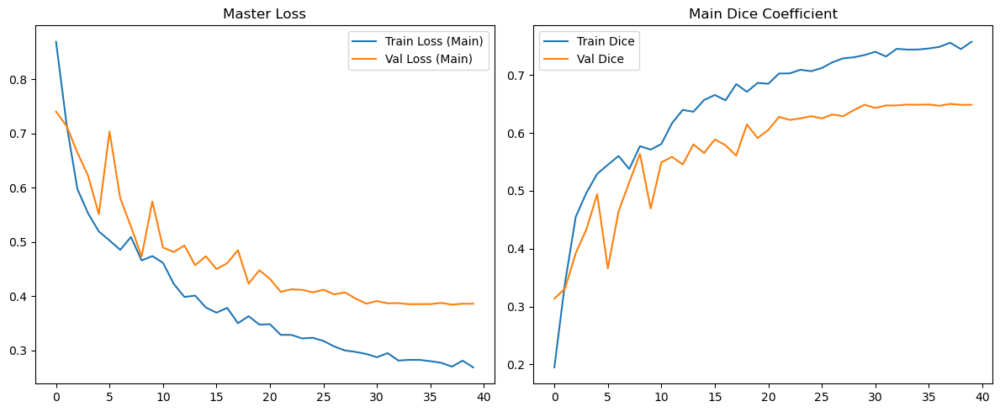

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, backend as K


K.clear_session()
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

TARGET_SIZE = (128, 128)
BATCH_SIZE = 16


class CustomGroupNormalization(layers.Layer):
    def __init__(self, groups=8, epsilon=1e-5, **kwargs):
        super(CustomGroupNormalization, self).__init__(**kwargs)
        self.groups = groups
        self.epsilon = epsilon

    def build(self, input_shape):
        self.gamma = self.add_weight(name='gamma', shape=(input_shape[-1],),
                                     initializer='ones', trainable=True)
        self.beta = self.add_weight(name='beta', shape=(input_shape[-1],),
                                    initializer='zeros', trainable=True)
        super(CustomGroupNormalization, self).build(input_shape)

    def call(self, x):
        input_shape = tf.shape(x)
        N, H, W, C = input_shape[0], input_shape[1], input_shape[2], input_shape[3]
        x_reshaped = tf.reshape(x, [N, H, W, self.groups, C // self.groups])
        mean, var = tf.nn.moments(x_reshaped, axes=[1, 2, 4], keepdims=True)
        x_normalized = (x_reshaped - mean) / tf.sqrt(var + self.epsilon)
        x_normalized = tf.reshape(x_normalized, input_shape)
        return self.gamma * x_normalized + self.beta

def load_data(indices, use_normalized=True, target_size=TARGET_SIZE):
    X, Y = [], []
    for idx in indices:
        if use_normalized:
            img = normalized_images[idx]
        else:
            img = cv2.imread(image_files[idx], cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        img = cv2.resize(img, target_size)
        X.append(img[..., np.newaxis])
      
        m = cv2.imread(mask_files[idx], cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        m = cv2.resize(m, target_size, interpolation=cv2.INTER_NEAREST)
        Y.append(m[..., np.newaxis])
    return np.stack(X), np.stack(Y)

print("Loading data...")
X_train_orig, Y_train_orig = load_data(train_indices, use_normalized=True)
X_val, Y_val = load_data(val_indices, use_normalized=True)
X_test, Y_test = load_data(test_indices, use_normalized=True)

aug_X, aug_Y = [], []
for pid, pairs in augmented_train_data.items():
    for (img_aug, mask_aug) in pairs:
        img_r = cv2.resize(img_aug, TARGET_SIZE).astype(np.float32)/255.0
        mask_r = cv2.resize(mask_aug, TARGET_SIZE, interpolation=cv2.INTER_NEAREST).astype(np.float32)/255.0
        aug_X.append(img_r[..., np.newaxis])
        aug_Y.append(mask_r[..., np.newaxis])

X_train = np.concatenate([X_train_orig, np.array(aug_X)], axis=0)
Y_train = np.concatenate([Y_train_orig, np.array(aug_Y)], axis=0)

Y_train_multi = [Y_train, Y_train, Y_train, Y_train]
Y_val_multi = [Y_val, Y_val, Y_val, Y_val]

smooth = 1e-6
def dice_coef(y_true, y_pred):
    y_true_f, y_pred_f = K.flatten(y_true), K.flatten(y_pred)
    inter = K.sum(y_true_f * y_pred_f)
    return (2 * inter + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def iou_coef(y_true, y_pred):
    y_true_f, y_pred_f = K.flatten(y_true), K.flatten(y_pred)
    inter = K.sum(y_true_f * y_pred_f)
    union = K.sum(y_true_f) + K.sum(y_pred_f) - inter
    return (inter + smooth) / (union + smooth)

def bce_dice_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    dice_loss = 1.0 - dice_coef(y_true, y_pred)
    return bce + dice_loss

def build_deep_supervised_unet(input_shape=(128,128,1)):
    inputs = layers.Input(input_shape)
    
    def conv_block(x, f):
        x = layers.Conv2D(f, 3, padding='same', kernel_initializer='he_normal')(x)
        x = CustomGroupNormalization(groups=8)(x) # استفاده از کلاس کاستوم ما
        x = layers.LeakyReLU(alpha=0.01)(x)
        
        x = layers.Conv2D(f, 3, padding='same', kernel_initializer='he_normal')(x)
        x = CustomGroupNormalization(groups=8)(x) # استفاده از کلاس کاستوم ما
        x = layers.LeakyReLU(alpha=0.01)(x)
        return x
        
    # --- Encoder ---
    c1 = conv_block(inputs, 64)
    p1 = layers.MaxPooling2D()(c1)
    
    c2 = conv_block(p1, 128)
    p2 = layers.MaxPooling2D()(c2)
    
    c3 = conv_block(p2, 256)
    p3 = layers.MaxPooling2D()(c3)
    
    c4 = conv_block(p3, 512)
    p4 = layers.MaxPooling2D()(c4)
    

    b = conv_block(p4, 1024)
    

    u4 = layers.Conv2DTranspose(512, 2, strides=2, padding='same')(b)
    u4 = layers.Concatenate()([u4, c4])
    d4 = conv_block(u4, 512)
    out4 = layers.Conv2D(1, 1, activation='sigmoid')(d4)
    out4 = layers.UpSampling2D(size=(8, 8), interpolation='bilinear', name='out4')(out4)
    
    u3 = layers.Conv2DTranspose(256, 2, strides=2, padding='same')(d4)
    u3 = layers.Concatenate()([u3, c3])
    d3 = conv_block(u3, 256)
    out3 = layers.Conv2D(1, 1, activation='sigmoid')(d3)
    out3 = layers.UpSampling2D(size=(4, 4), interpolation='bilinear', name='out3')(out3)
    
    u2 = layers.Conv2DTranspose(128, 2, strides=2, padding='same')(d3)
    u2 = layers.Concatenate()([u2, c2])
    d2 = conv_block(u2, 128)
    out2 = layers.Conv2D(1, 1, activation='sigmoid')(d2)
    out2 = layers.UpSampling2D(size=(2, 2), interpolation='bilinear', name='out2')(out2)
    
    u1 = layers.Conv2DTranspose(64, 2, strides=2, padding='same')(d2)
    u1 = layers.Concatenate()([u1, c1])
    d1 = conv_block(u1, 64)
    out1 = layers.Conv2D(1, 1, activation='sigmoid', name='out1')(d1)
    
    return models.Model(inputs, [out1, out2, out3, out4])

model = build_deep_supervised_unet(input_shape=(128,128,1))

losses = {
    "out1": bce_dice_loss, "out2": bce_dice_loss, 
    "out3": bce_dice_loss, "out4": bce_dice_loss,
}
loss_weights = {"out1": 1.0, "out2": 0.5, "out3": 0.25, "out4": 0.125}
metrics = {"out1": [dice_coef, iou_coef]}

lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=3e-4,
    decay_steps=40 * (len(X_train) // BATCH_SIZE),
    alpha=1e-5
)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
              loss=losses,
              loss_weights=loss_weights,
              metrics=metrics)

earlystop = tf.keras.callbacks.EarlyStopping(monitor='val_out1_dice_coef', mode='max', patience=12, restore_best_weights=True)
checkpoint = tf.keras.callbacks.ModelCheckpoint('deep_unet_best.keras', monitor='val_out1_dice_coef', mode='max', save_best_only=True, verbose=1)

print("\n--- Starting Master SOTA Training (Deeply Supervised U-Net) ---")
history = model.fit(X_train, Y_train_multi,
                    validation_data=(X_val, Y_val_multi),
                    batch_size=BATCH_SIZE,
                    epochs=40,
                    callbacks=[earlystop, checkpoint])


print("\n--- Final SOTA Evaluation on Test Set ---")
predictions = model.predict(X_test, batch_size=BATCH_SIZE)
final_preds = predictions[0]

y_test_f = Y_test.flatten()
final_preds_f = final_preds.flatten()

intersection = np.sum(y_test_f * final_preds_f)
final_dice = (2. * intersection + smooth) / (np.sum(y_test_f) + np.sum(final_preds_f) + smooth)
final_iou = (intersection + smooth) / (np.sum(y_test_f) + np.sum(final_preds_f) - intersection + smooth)
final_bce = -np.mean(y_test_f * np.log(final_preds_f + 1e-7) + (1 - y_test_f) * np.log(1 - final_preds_f + 1e-7))

print("\n==========================================")
print("🎯 MASTER SOTA RESULTS (Deeply Supervised nnU-Net Style) 🎯")
print("==========================================")
print(f"Final Test BCE Loss: {final_bce:.4f}")
print(f"Final Test Dice:     {final_dice:.4f}")
print(f"Final Test IoU:      {final_iou:.4f}")
print("==========================================")

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['out1_loss'], label='Train Loss (Main)')
plt.plot(history.history['val_out1_loss'], label='Val Loss (Main)')
plt.title("Master Loss"); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['out1_dice_coef'], label='Train Dice')
plt.plot(history.history['val_out1_dice_coef'], label='Val Dice')
plt.title("Main Dice Coefficient"); plt.legend()
plt.tight_layout()
plt.show()